# Preprocessing Pipeline — `Decisao` Classification

Transforms the raw jurisprudence data into a clean, model-ready dataset for predicting the outcome of appellate decisions (`Decisao`).

## Section 1 — Setup & Loading

All dependencies are imported here, including `src.config.MODEL_REGISTRY` (used in Section 6 for the per-model tokenizer diagnostic) and.

In [31]:
import json
import re
import sys
import unicodedata
from pathlib import Path

import ijson
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

sys.path.insert(0, str(Path('../..').resolve()))
from src.config import MODEL_REGISTRY

DATA_DIR    = Path('../../data/1_raw')
OUTPUT_DIR  = Path('../../data/2_processed')
SPLITS_PATH = OUTPUT_DIR / 'splits_grupo3.csv'
OUTPUT_DIR.mkdir(exist_ok=True)

pipeline_funnel = {}

FREQUENCY_THRESHOLD = 250

In [32]:
COURTS = ['TRC', 'TRE', 'TRG', 'TRL', 'TRP']

NEEDED_FIELDS = ['ImportJurisprudenciaId', 'Sumario', 'Observacoes', 'TipoDecisao']

frames = []
for court in COURTS:
    path = DATA_DIR / f'{court}.json'
    records = []
    with open(path, 'rb') as f:
        for rec in ijson.items(f, 'item'):
            records.append({k: rec.get(k) for k in NEEDED_FIELDS})
    df = pd.DataFrame(records)
    df['source'] = court
    frames.append(df)

all_data = pd.concat(frames, ignore_index=True)
pipeline_funnel['Raw records loaded'] = len(all_data)

print(f'Total records loaded : {len(all_data):,}')
print(f'Courts               : {all_data["source"].nunique()}')
print()
all_data['source'].value_counts().rename('records').to_frame()

Total records loaded : 35,815
Courts               : 5



,records
source,
TRL,12145
TRE,7576
TRG,6714
TRP,4825
TRC,4555


In [33]:
def parse_decisao(obs):
    if not obs or not isinstance(obs, str):
        return None
    m = re.search(r'Decis[aã]o:\s*(.+)', obs)
    return m.group(1).split('\n')[0].strip() if m else None

all_data['Decisao'] = all_data['Observacoes'].apply(parse_decisao)

before_drop = len(all_data)
all_data = all_data[all_data['Decisao'].notna()].reset_index(drop=True)
pipeline_funnel['With parsed Decisao'] = len(all_data)

print(f'Total records loaded          : {before_drop:,}')
print(f'Records with Decisao          : {len(all_data):,}  ({len(all_data)/before_drop*100:.1f}%)')
print(f'Dropped (no Decisao)          : {before_drop - len(all_data):,}')
print(f'Unique Decisao values         : {all_data["Decisao"].nunique():,}')

Total records loaded          : 35,815
Records with Decisao          : 15,484  (43.2%)
Dropped (no Decisao)          : 20,331
Unique Decisao values         : 916


### 1.1 Join the Train / Val / Test Split Assignment (from `04_Data_Split`)

`04_Data_Split.ipynb` already decided, once, which record belongs to train/val/test and which duplicate-group (`group_id`) it belongs to.

In [34]:
splits_df = pd.read_csv(SPLITS_PATH)[
    ['source', 'ImportJurisprudenciaId', 'Decisao', 'group_id', 'split', 'cv_fold']
].rename(columns={'Decisao': 'Decisao_split'})

before_join = len(all_data)
all_data = all_data.merge(splits_df, on=['source', 'ImportJurisprudenciaId'], how='inner')
pipeline_funnel['Matched to 04 split assignment'] = len(all_data)

print(f'Records before join (this notebook)   : {before_join:,}')
print(f'Records after join  (04 ∩ this notebook): {len(all_data):,}')
print(f'Dropped (absent from 04\'s split export) : {before_join - len(all_data):,}')

mismatch = int((all_data['Decisao'] != all_data['Decisao_split']).sum())
print(f'\nDecisao mismatches vs. 04\'s export      : {mismatch:,}')
assert mismatch == 0, (
    'parse_decisao has drifted between 04_Data_Split and 06_Preprocessing_Decisao — '
    'the two notebooks must extract identical Decisao values for the join to be valid.'
)
all_data = all_data.drop(columns='Decisao_split')

print('\nRecords per split:')
print(all_data['split'].value_counts().to_string())

Records before join (this notebook)   : 15,484
Records after join  (04 ∩ this notebook): 14,240
Dropped (absent from 04's split export) : 1,244

Decisao mismatches vs. 04's export      : 0

Records per split:
split
train    10679
test      2137
val       1424


## Section 2 — Label Normalization

The `Decisao` strings extracted from `Observacoes` contain variation only.

In [35]:
n_before = all_data['Decisao'].nunique()
print(f'Unique Decisao values before normalization : {n_before:,}')

all_data['Decisao'] = (
    all_data['Decisao']
    .str.strip()
    .str.upper()
    .str.replace(r'\s+', ' ', regex=True)
)

n_after = all_data['Decisao'].nunique()
print(f'Unique Decisao values after cosmetic normalization : {n_after:,}')
print(f'Reduction                                          : {n_before - n_after:,}')

Unique Decisao values before normalization : 109
Unique Decisao values after cosmetic normalization : 109
Reduction                                          : 0


## Section 3 — Text Normalization on `Sumario`

The `Sumario` (summary text, used as the model input) can contain encoding artefacts from the scraping pipeline: inconsistent Unicode.

In [36]:
all_data['Sumario_raw'] = all_data['Sumario'].copy()

_CTRL_RE = re.compile(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f\xa0]')
_WS_RE   = re.compile(r'\s+')

def normalize_text(text):
    """Encoding/whitespace clean-up only — case is preserved for cased-model input."""
    if not isinstance(text, str):
        return text
    text = unicodedata.normalize('NFC', text)
    text = _CTRL_RE.sub(' ', text)
    text = _WS_RE.sub(' ', text).strip()
    return text

all_data['Sumario'] = all_data['Sumario'].apply(normalize_text)

changed = (all_data['Sumario'] != all_data['Sumario_raw']).sum()
print(f'Sumario entries modified by normalization : {changed:,} / {len(all_data):,}  ({changed/len(all_data)*100:.1f}%)')

Sumario entries modified by normalization : 13,070 / 14,240  (91.8%)


## Section 4 — Redundant-Record Removal (via `04`'s Duplicate Groups)

`04_Data_Split` already grouped near-duplicate `Sumario` texts and repeated `NumeroProcesso` values into `group_id`, and guaranteed.

In [37]:
before = len(all_data)
print(f'Rows before dedup (via group_id) : {before:,}')

groups_per_split = all_data.groupby('group_id')['split'].nunique()
assert (groups_per_split == 1).all(), (
    'A group_id spans more than one split -- 04_Data_Split\'s contamination guard has '
    'been violated somewhere between the join (§1.1) and Section 4.'
)

dup_mask = all_data.duplicated(subset='group_id', keep='first')

dup_by_source = (
    all_data.loc[dup_mask, 'source']
    .value_counts()
    .rename('removed')
    .to_frame()
    .assign(pct=lambda d: (d['removed'] / before * 100).round(2))
)
print('\nDuplicates removed per source:')
print(dup_by_source.to_string())

dup_by_split = all_data.loc[dup_mask, 'split'].value_counts()
print('\nDuplicates removed per split:')
print(dup_by_split.to_string())

all_data = all_data.drop(index=all_data.index[dup_mask]).reset_index(drop=True)
pipeline_funnel['After dedup (group_id)'] = len(all_data)
print(f'\nRows removed  : {before - len(all_data):,}')
print(f'Rows after    : {len(all_data):,}')

Rows before dedup (via group_id) : 14,240

Duplicates removed per source:
        removed   pct
source               
TRL          35  0.25
TRP          24  0.17
TRE          19  0.13
TRC          17  0.12
TRG          10  0.07

Duplicates removed per split:
split
train    79
test     16
val      10

Rows removed  : 105
Rows after    : 14,135


## Section 5 — Minimum Length Filter

The EDA (section 2.3) flagged entries with fewer than 20 whitespace-split tokens as potentially uninformative: placeholder text.

In [38]:
WORD_THRESHOLD = 20

before     = len(all_data)
word_counts = all_data['Sumario'].str.split().str.len()
short_mask  = word_counts.fillna(0) < WORD_THRESHOLD

print(f'Rows before filter           : {before:,}')
print(f'Rows removed  (< {WORD_THRESHOLD} words)  : {short_mask.sum():,}  ({short_mask.sum()/before*100:.2f}%)')

all_data = all_data[~short_mask].reset_index(drop=True)
pipeline_funnel['After min-length filter'] = len(all_data)
print(f'Rows after filter            : {len(all_data):,}')

Rows before filter           : 14,135
Rows removed  (< 20 words)  : 14  (0.10%)
Rows after filter            : 14,121


## Section 6 — Token-Length Diagnostic (per fine-tuning model)

All encoders (on the src.config MODEL_REGISTRY) share the 512-token limit.

In [39]:
token_count_cols = {}
over_limit_masks = {}

for slug, cfg in MODEL_REGISTRY.items():
    print(f'Loading tokenizer: {cfg.hf_id}  (revision={cfg.revision}) ...')
    tok = AutoTokenizer.from_pretrained(cfg.hf_id, revision=cfg.revision)
    encodings = tok(
        all_data['Sumario'].tolist(),
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_attention_mask=False,
    )
    counts = [len(ids) for ids in encodings['input_ids']]
    col = f'token_count_{slug}'
    all_data[col] = counts
    token_count_cols[slug] = col
    over_limit_masks[slug] = all_data[col] > cfg.max_length

print()
print(f'Tokenization complete for all {len(MODEL_REGISTRY)} models.')

Loading tokenizer: PORTULAN/albertina-100m-portuguese-ptpt-encoder  (revision=d15e086005cdab26d746d9113984cc654439df2b) ...


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (728 > 512). Running this sequence through the model will result in indexing errors


Loading tokenizer: eduagarcia/RoBERTaLexPT-base  (revision=9dea30875c93dc2d33b35c2338dfc93c86715b9e) ...


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (532 > 512). Running this sequence through the model will result in indexing errors


Loading tokenizer: dominguesm/legal-bert-base-cased-ptbr  (revision=356e007ddd856c3028bd61962041952b6aa2a53b) ...
Loading tokenizer: neuralmind/bert-base-portuguese-cased  (revision=94d69c95f98f7d5b2a8700c420230ae10def0baa) ...
Loading tokenizer: FacebookAI/xlm-roberta-base  (revision=e73636d4f797dec63c3081bb6ed5c7b0bb3f2089) ...


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (552 > 512). Running this sequence through the model will result in indexing errors


... (3 outputs left out)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (647 > 512). Running this sequence through the model will result in indexing errors


Loading tokenizer: PORTULAN/serafim-900m-portuguese-pt-sentence-encoder  (revision=8b6aac1431bf56dd4b8f6a27a98ea78d3a7c5d31) ...


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (647 > 512). Running this sequence through the model will result in indexing errors



Tokenization complete for all 8 models.


In [40]:
rows = []
for slug, cfg in MODEL_REGISTRY.items():
    col = token_count_cols[slug]
    mask = over_limit_masks[slug]
    rows.append({
        'model': cfg.display_name,
        'slug': slug,
        'n_over_limit': int(mask.sum()),
        'pct_over_limit': round(mask.mean() * 100, 2),
        'max_token_len': int(all_data[col].max()),
        'median_token_len': int(all_data[col].median()),
    })

summary_df = pd.DataFrame(rows).set_index('slug')
print(f'Records analysed: {len(all_data):,}\n')
print(summary_df.to_string())

Records analysed: 14,121

                                                model  n_over_limit  pct_over_limit  max_token_len  median_token_len
slug                                                                                                                
albertina                      Albertina PT-PT (100M)          4868           34.47           7650               395
robertalexpt                        RoBERTaLexPT-base          1420           10.06           4428               225
legalbert                     Legal-BERT PT-BR (base)          1430           10.13           4404               225
bertimbau                            BERTimbau (base)          1853           13.12           4817               250
xlmr                                 XLM-RoBERTa-base          2103           14.89           5064               264
albertina_900m                 Albertina PT-PT (900M)          3765           26.66           6572               342
albertina_1b5                  Alberti

In [41]:
_preview_freq = all_data.loc[all_data['split'] == 'train', 'Decisao'].value_counts()
_preview_classes = _preview_freq[_preview_freq > FREQUENCY_THRESHOLD].index

bias_rows = []
for slug, cfg in MODEL_REGISTRY.items():
    mask = over_limit_masks[slug]
    sub = all_data[all_data['Decisao'].isin(_preview_classes)]
    over = sub[mask.reindex(sub.index, fill_value=False)]
    within = sub[~mask.reindex(sub.index, fill_value=False)]
    over_dist = over['Decisao'].value_counts(normalize=True) * 100
    within_dist = within['Decisao'].value_counts(normalize=True) * 100
    for cls in _preview_classes:
        bias_rows.append({
            'model': slug,
            'Decisao': cls,
            'pct_within_over_limit_group': round(over_dist.get(cls, 0.0), 2),
            'pct_within_normal_group': round(within_dist.get(cls, 0.0), 2),
        })

bias_df = pd.DataFrame(bias_rows)
pivot = bias_df.pivot(index='Decisao', columns='model', values='pct_within_over_limit_group')
print('% share of each class WITHIN the over-512-token group, per model tokenizer:')
print('(compare against the overall class shares in Section 8 — large deviations would')
print(' indicate long documents are disproportionately linked to a specific outcome)')
print()
print(pivot.to_string())

% share of each class WITHIN the over-512-token group, per model tokenizer:
(compare against the overall class shares in Section 8 — large deviations would
 indicate long documents are disproportionately linked to a specific outcome)

model                           albertina  albertina_1b5  albertina_900m  bertimbau  legalbert  robertalexpt  serafim_900m   xlmr
Decisao                                                                                                                          
APELAÇÃO IMPROCEDENTE                4.21           3.94            3.94       4.04       3.93          3.74          3.94   3.81
CONFIRMADA                          30.07          29.79           29.79      26.86      25.57         25.23         29.79  27.23
CONFIRMADA A DECISÃO RECORRIDA       2.08           1.74            1.74       1.19       1.35          1.14          1.74   1.39
CONFIRMAÇÃO                          4.21           4.40            4.40       4.91       4.66          4.67       

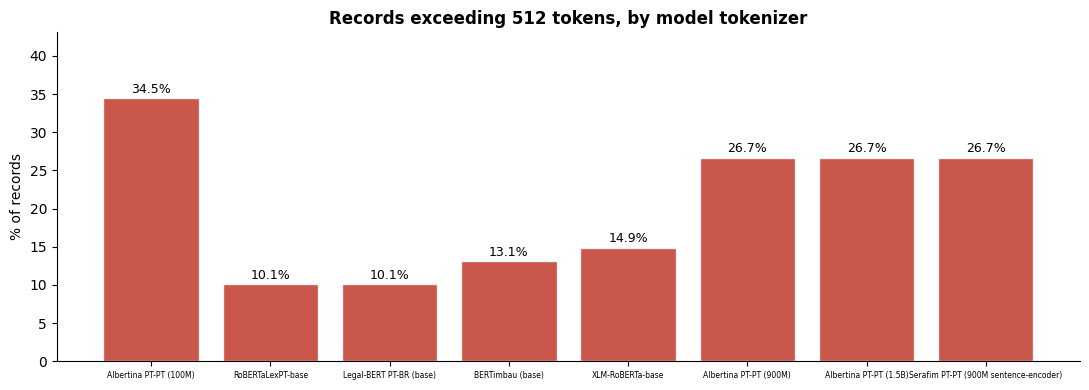

In [42]:
fig, ax = plt.subplots(figsize=(11, 4))
models_plot = [cfg.display_name for cfg in MODEL_REGISTRY.values()]
pcts_plot = [summary_df.loc[slug, 'pct_over_limit'] for slug in MODEL_REGISTRY]

bars = ax.bar(models_plot, pcts_plot, color='#C0392B', alpha=0.85, edgecolor='white')
for bar, val in zip(bars, pcts_plot):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9)
    ax.tick_params(axis='x', labelsize=5.5)

ax.set_title('Records exceeding 512 tokens, by model tokenizer', fontsize=12, fontweight='bold')
ax.set_ylabel('% of records')
ax.set_ylim(0, max(pcts_plot) * 1.25)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../../reports/figures/token_overlimit_by_model.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 7 — Label Leakage Detection & Filtering

The EDA (`02_EDA_Decisao.ipynb` §5.6.2, `05_EDA_Group3_Decisao_Train.ipynb` §4) flagged that some `Sumario` texts state the outcome.

In [43]:
'''import unicodedata as _ud

def _strip_accents(s):
    return ''.join(c for c in _ud.normalize('NFD', s) if _ud.category(c) != 'Mn')

_sumario_norm_for_leakage = all_data['Sumario'].fillna('').apply(lambda s: _strip_accents(s.lower()))

# Trigger phrases congruent with the record's OWN canonical label (post Section-2 merge).
# Deliberately narrow: only labels with a near-unambiguous outcome-revealing phrase get an
# entry; labels without one here are never flagged (avoids false positives from generic
# legal vocabulary that doesn't actually restate the record's own outcome).
LEAKAGE_TRIGGERS = {
    'CONFIRMADA': [r'confirma(?:da|ndo|-se|r)?\s+(?:a\s+)?(?:decis[aã]o|senten[cç]a)'],
    'IMPROCEDENTE': [r'\bimprocedente\b', r'n[aã]o\s+provid[oa]',
                     r'negad[oa]\s+provimento', r'negar\s+provimento'],
    'PROCEDENTE': [r'\bprocedente\b', r'\bprovid[oa]\b(?!\s+parcial)'],
    'REVOGADA': [r'revog(?:ada|ando|ar|a-se)\s+(?:a\s+)?(?:decis[aã]o|senten[cç]a)'],
    'REVOGADA EM PARTE': [r'revog(?:ada|ar)\s+(?:em\s+)?parte', r'parcialmente\s+revogad[oa]'],
    'PARCIALMENTE PROCEDENTE': [r'parcialmente\s+procedente'],
    'PROVIDO PARCIALMENTE': [r'parcialmente\s+provid[oa]', r'provid[oa]\s+parcialmente'],
    'ANULADA': [r'anulad[oa]\s+(?:a\s+)?(?:decis[aã]o|senten[cç]a)'],
}
_compiled_triggers = {
    label: re.compile('|'.join(pats), re.IGNORECASE) for label, pats in LEAKAGE_TRIGGERS.items()
}

def _is_leaking(text_norm, label):
    rx = _compiled_triggers.get(label)
    return bool(rx.search(text_norm)) if rx is not None else False

all_data['label_leakage'] = [
    _is_leaking(t, lbl) for t, lbl in zip(_sumario_norm_for_leakage, all_data['Decisao'])
]

n_leak = int(all_data['label_leakage'].sum())
print(f'Records flagged as label leakage : {n_leak:,} / {len(all_data):,}  ({n_leak/len(all_data)*100:.2f}%)')
'''

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jc/ggdhgrys23xgcrxc0fly4jjc0000gn/T/ipykernel_3401/1092731771.py:1: SyntaxWarning: invalid escape sequence '\s'
  '''import unicodedata as _ud


"import unicodedata as _ud\n\ndef _strip_accents(s):\n    return ''.join(c for c in _ud.normalize('NFD', s) if _ud.category(c) != 'Mn')\n\n_sumario_norm_for_leakage = all_data['Sumario'].fillna('').apply(lambda s: _strip_accents(s.lower()))\n\n# Trigger phrases congruent with the record's OWN canonical label (post Section-2 merge).\n# Deliberately narrow: only labels with a near-unambiguous outcome-revealing phrase get an\n# entry; labels without one here are never flagged (avoids false positives from generic\n# legal vocabulary that doesn't actually restate the record's own outcome).\nLEAKAGE_TRIGGERS = {\n    'CONFIRMADA': [r'confirma(?:da|ndo|-se|r)?\\s+(?:a\\s+)?(?:decis[aã]o|senten[cç]a)'],\n    'IMPROCEDENTE': [r'\x08improcedente\x08', r'n[aã]o\\s+provid[oa]',\n                     r'negad[oa]\\s+provimento', r'negar\\s+provimento'],\n    'PROCEDENTE': [r'\x08procedente\x08', r'\x08provid[oa]\x08(?!\\s+parcial)'],\n    'REVOGADA': [r'revog(?:ada|ando|ar|a-se)\\s+(?:a\\s+)?(?:deci

In [44]:
'''# ── Per-class leakage breakdown (classes that will survive the frequency filter,
# frequency computed on train only — see Section 8) ────────────────────────────────
_freq_preview = all_data.loc[all_data['split'] == 'train', 'Decisao'].value_counts()
_top_classes_preview = _freq_preview[_freq_preview > FREQUENCY_THRESHOLD].index

leak_by_class = (
    all_data[all_data['Decisao'].isin(_top_classes_preview)]
    .groupby('Decisao')['label_leakage']
    .agg(n_flagged='sum', n_total='count')
)
leak_by_class['pct'] = (leak_by_class['n_flagged'] / leak_by_class['n_total'] * 100).round(2)
print(leak_by_class.sort_values('pct', ascending=False).to_string())

EXCLUDE_LEAKAGE = True
if EXCLUDE_LEAKAGE:
    before_leak_filter = len(all_data)
    all_data = all_data[~all_data['label_leakage']].reset_index(drop=True)
    pipeline_funnel['After leakage filter'] = len(all_data)
    print(f'\nExcluded {before_leak_filter - len(all_data):,} leaking records '
          f'({(before_leak_filter - len(all_data))/before_leak_filter*100:.2f}% of records at this stage).')
else:
    pipeline_funnel['After leakage filter'] = len(all_data)
    print('\nEXCLUDE_LEAKAGE=False — leaking records retained (flag column only).')
'''

"# ── Per-class leakage breakdown (classes that will survive the frequency filter,\n# frequency computed on train only — see Section 8) ────────────────────────────────\n_freq_preview = all_data.loc[all_data['split'] == 'train', 'Decisao'].value_counts()\n_top_classes_preview = _freq_preview[_freq_preview > FREQUENCY_THRESHOLD].index\n\nleak_by_class = (\n    all_data[all_data['Decisao'].isin(_top_classes_preview)]\n    .groupby('Decisao')['label_leakage']\n    .agg(n_flagged='sum', n_total='count')\n)\nleak_by_class['pct'] = (leak_by_class['n_flagged'] / leak_by_class['n_total'] * 100).round(2)\nprint(leak_by_class.sort_values('pct', ascending=False).to_string())\n\nEXCLUDE_LEAKAGE = True\nif EXCLUDE_LEAKAGE:\n    before_leak_filter = len(all_data)\n    all_data = all_data[~all_data['label_leakage']].reset_index(drop=True)\n    pipeline_funnel['After leakage filter'] = len(all_data)\n    print(f'\nExcluded {before_leak_filter - len(all_data):,} leaking records '\n          f'({(before

## Section 8 — Long-Tail Frequency Filter

Portuguese court decisions follow a Zipfian distribution: a handful of outcomes dominate while hundreds of label variants appear rarely.

In [45]:
print(f'Starting point  →  {len(all_data):>6,} documents  |  {all_data["Decisao"].nunique():>4} unique classes')

train_class_freq = all_data.loc[all_data['split'] == 'train', 'Decisao'].value_counts()

frequent_classes = train_class_freq[train_class_freq > FREQUENCY_THRESHOLD].index

df_filtered = (
    all_data[all_data['Decisao'].isin(frequent_classes)]
    .reset_index(drop=True)
)
pipeline_funnel['After frequency filter (train-driven)'] = len(df_filtered)

n_docs    = len(df_filtered)
n_classes = df_filtered['Decisao'].nunique()
n_docs_dropped    = len(all_data) - n_docs
n_classes_dropped = all_data['Decisao'].nunique() - n_classes

print()
print(f'Documents  : {n_docs:>6,}')
print(f'Classes    : {n_classes:>6,}')
print()
print(f'   Docs  dropped : {n_docs_dropped:,}  ({100 * n_docs_dropped / len(all_data):.1f}% of pre-filter)')
print(f'   Classes pruned: {n_classes_dropped}  ({100 * n_classes_dropped / all_data["Decisao"].nunique():.1f}% of pre-filter classes)')

print('\nRecords per split after frequency filter:')
print(df_filtered['split'].value_counts().to_string())

train_classes = set(df_filtered.loc[df_filtered['split'] == 'train', 'Decisao'].unique())
for other_split in ['val', 'test']:
    split_classes = set(df_filtered.loc[df_filtered['split'] == other_split, 'Decisao'].unique())
    orphans = train_classes - split_classes
    print(f'\nTrain classes absent from {other_split} : {len(orphans)}')
    if orphans:
        print(sorted(orphans))

Starting point  →  14,121 documents  |    99 unique classes

Documents  : 10,153
Classes    :     10

   Docs  dropped : 3,968  (28.1% of pre-filter)
   Classes pruned: 89  (89.9% of pre-filter classes)

Records per split after frequency filter:
split
train    7614
test     1523
val      1016

Train classes absent from val : 0

Train classes absent from test : 0


df_filtered — class distribution (10,153 records, 10 classes)

Class                                                     Count        %
------------------------------------------------------------------------
CONFIRMADA                                                3,405   33.54%
IMPROCEDENTE                                              1,851   18.23%
REVOGADA                                                  1,392   13.71%
PROCEDENTE                                                  722    7.11%
NÃO PROVIDO                                                 579    5.70%
APELAÇÃO IMPROCEDENTE                                       540    5.32%
CONFIRMAÇÃO                                                 479    4.72%
REVOGADA EM PARTE                                           407    4.01%
PARCIALMENTE PROCEDENTE                                     404    3.98%
CONFIRMADA A DECISÃO RECORRIDA                              374    3.68%


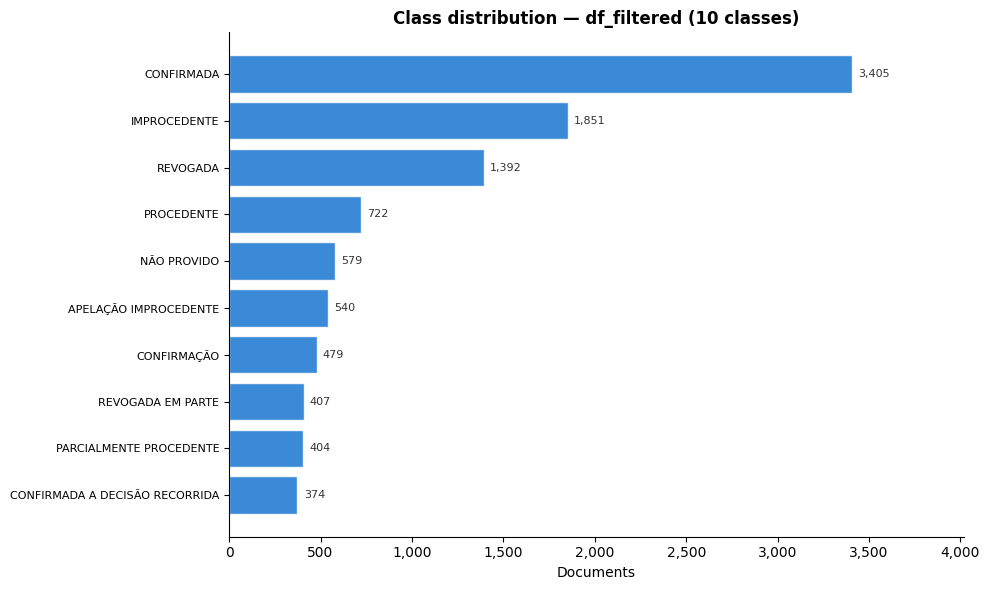

In [46]:
import matplotlib.ticker as mticker

vc  = df_filtered['Decisao'].value_counts()
pct = (vc / len(df_filtered) * 100).round(2)

print(f'df_filtered — class distribution ({len(df_filtered):,} records, {len(vc)} classes)')
print()
print(f'{"Class":<55} {"Count":>7}  {"  %":>7}')
print('-' * 72)
for label, count in vc.items():
    print(f'{label:<55} {count:>7,}  {pct[label]:>6.2f}%')

fig, ax = plt.subplots(figsize=(10, max(6, 0.45 * len(vc))))
bars = ax.barh(vc.index[::-1], vc.values[::-1], color='#1976D2', alpha=0.85, edgecolor='white')

for bar, val in zip(bars, vc.values[::-1]):
    ax.text(bar.get_width() + vc.max() * 0.01, bar.get_y() + bar.get_height() / 2,
            f'{int(val):,}', va='center', fontsize=8, color='#333333')

ax.set_title(f'Class distribution — df_filtered ({len(vc)} classes)', fontsize=12, fontweight='bold')
ax.set_xlabel('Documents', fontsize=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.tick_params(axis='y', labelsize=8)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(right=vc.max() * 1.18)
plt.tight_layout()
plt.savefig('../../reports/figures/class_distribution_filtered.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 9 — Final Export

`df_filtered` is written to `../../data/2_processed/` as a UTF-8 CSV file.

In [47]:
EXPORT_COLS = [
    'ImportJurisprudenciaId', 'source', 'Sumario_raw', 'Sumario', 'Decisao', 'TipoDecisao',
    'group_id', 'split', 'cv_fold',
]

assert set(df_filtered['split'].unique()) <= {'train', 'val', 'test'}, (
    'Unexpected split label — 04_Data_Split and this notebook have drifted.'
)

if 'label_leakage' in df_filtered.columns:
    assert not df_filtered['label_leakage'].any(), (
        'df_filtered still contains leakage-flagged records — set EXCLUDE_LEAKAGE=True '
        'in Section 7 before exporting.'
    )

export_path = OUTPUT_DIR / 'preprocessed_grupo3.csv'
df_filtered[EXPORT_COLS].to_csv(export_path, index=False, encoding='utf-8')
print(f'Exported : {export_path}  ({len(df_filtered):,} rows)')

from sklearn.preprocessing import LabelEncoder
_le = LabelEncoder().fit(df_filtered['Decisao'])
labels_g3 = list(_le.classes_)
label2id_g3 = {cls: int(i) for i, cls in enumerate(_le.classes_)}
id2label_g3 = {int(i): cls for i, cls in enumerate(_le.classes_)}

_lbl_path = OUTPUT_DIR / 'label2id_grupo3.json'
with open(_lbl_path, 'w', encoding='utf-8') as _f:
    json.dump(
        {'labels': labels_g3, 'label2id': label2id_g3, 'id2label': id2label_g3},
        _f, ensure_ascii=False, indent=2,
    )
print(f'Label mapping saved -> {_lbl_path}  ({len(label2id_g3)} classes)')

Exported : ../../data/2_processed/preprocessed_grupo3.csv  (10,153 rows)
Label mapping saved -> ../../data/2_processed/label2id_grupo3.json  (10 classes)


In [48]:
vc = df_filtered['Decisao'].value_counts()

print('=== Pipeline ===')
raw_total = next(iter(pipeline_funnel.values()))
prev = None
for stage, count in pipeline_funnel.items():
    if prev is None:
        print(f'  {stage:<28} : {count:>7,}')
    else:
        print(f'  {stage:<28} : {count:>7,}   (-{prev - count:,}, {count/raw_total*100:.1f}% of raw)')
    prev = count
print()

print('=== Split breakdown (df_filtered) ===')
print(df_filtered['split'].value_counts().to_string())
print()

print('=== preprocessed_grupo3 (df_filtered) ===')
print(f'  Total records      : {len(df_filtered):,}')
print(f'  Unique classes     : {df_filtered["Decisao"].nunique()}')
print()
print(vc.to_frame('count').assign(pct=(vc / len(df_filtered) * 100).round(2)).to_string())

=== Pipeline ===
  Raw records loaded           :  35,815
  With parsed Decisao          :  15,484   (-20,331, 43.2% of raw)
  Matched to 04 split assignment :  14,240   (-1,244, 39.8% of raw)
  After dedup (group_id)       :  14,135   (-105, 39.5% of raw)
  After min-length filter      :  14,121   (-14, 39.4% of raw)
  After frequency filter (train-driven) :  10,153   (-3,968, 28.3% of raw)

=== Split breakdown (df_filtered) ===
split
train    7614
test     1523
val      1016

=== preprocessed_grupo3 (df_filtered) ===
  Total records      : 10,153
  Unique classes     : 10

                                count    pct
Decisao                                     
CONFIRMADA                       3405  33.54
IMPROCEDENTE                     1851  18.23
REVOGADA                         1392  13.71
PROCEDENTE                        722   7.11
NÃO PROVIDO                       579   5.70
APELAÇÃO IMPROCEDENTE             540   5.32
CONFIRMAÇÃO                       479   4.72
REVOGADA EM P

### 9.1 Per-Court Composition (diagnostic)

Not a filtering step.

In [49]:
court_split = (
    df_filtered.groupby(["split", "source"]).size().unstack("source").fillna(0).astype(int)
    .reindex(["train", "val", "test"])
)
court_split_pct = court_split.div(court_split.sum(axis=1), axis=0).mul(100).round(1)

print("=== Records per court, per split (df_filtered) ===")
print(court_split.to_string())
print()
print("=== % share per court, per split ===")
print(court_split_pct.to_string())

min_court = court_split_pct.loc["train"].idxmin()
min_pct = court_split_pct.loc["train"].min()
msg = (
    "Smallest court share in train: " + str(min_court) + " (" + str(min_pct) + "%) "
    "— report this court's metrics separately, not just in aggregate; a small sample "
    "size there makes per-class recall noisy."
)
print()
print(msg)

=== Records per court, per split (df_filtered) ===
source   TRC  TRE  TRG   TRL   TRP
split                             
train   2377  282  673  2313  1969
val      323   39   87   314   253
test     493   56  138   455   381

=== % share per court, per split ===
source   TRC  TRE  TRG   TRL   TRP
split                             
train   31.2  3.7  8.8  30.4  25.9
val     31.8  3.8  8.6  30.9  24.9
test    32.4  3.7  9.1  29.9  25.0

Smallest court share in train: TRE (3.7%) — report this court's metrics separately, not just in aggregate; a small sample size there makes per-class recall noisy.
